In [2]:
from google.colab import files
import pandas as pd

uploaded = files.upload()



Saving movie_summary.csv to movie_summary (1).csv


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("movie_summary.csv")
df.head()

,movieId,title,genres,rating_count,average_rating
0,356,Forrest Gump (1994),Comedy|Drama|Romance|War,329,4.16
1,318,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.43
2,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,4.20
3,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,279,4.16
4,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278,4.19


In [4]:

print("Kích thước:", df.shape)
print("Cột:", df.columns.tolist())
print("Giá trị thiếu theo cột:\n", df.isna().sum())

rated = df[df["rating_count"] > 0].copy()
print("Số phim có đánh giá:", len(rated))
print("Tổng lượt rating:", rated["rating_count"].sum())

Kích thước: (9724, 5)
Cột: ['movieId', 'title', 'genres', 'rating_count', 'average_rating']
Giá trị thiếu theo cột:
 movieId           0
title             0
genres            0
rating_count      0
average_rating    0
dtype: int64
Số phim có đánh giá: 9724
Tổng lượt rating: 100836


In [5]:
# Thống kê mô tả rating_count
desc = rated["rating_count"].describe(percentiles=[.25, .5, .75, .90, .95, .99])
display(desc.to_frame(name="rating_count"))

,rating_count
count,9724.000000
mean,10.369807
std,22.401005
min,1.000000
25%,1.000000
50%,3.000000
75%,9.000000
90%,27.000000
95%,47.000000
99%,114.540000


In [6]:
# Top 10 phim phổ biến
top10 = rated.sort_values(["rating_count", "average_rating"], ascending=[False, False]).head(10)
display(top10[["movieId", "title", "genres", "rating_count", "average_rating"]])
top10.to_csv("top10_phim_pho_bien.csv", index=False, encoding="utf-8-sig")

,movieId,title,genres,rating_count,average_rating
0,356,Forrest Gump (1994),Comedy|Drama|Romance|War,329,4.16
1,318,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.43
2,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,4.20
3,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,279,4.16
4,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278,4.19
5,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251,4.23
6,480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,238,3.75
7,110,Braveheart (1995),Action|Drama|War,237,4.03
8,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,224,3.97
9,527,Schindler's List (1993),Drama|War,220,4.22


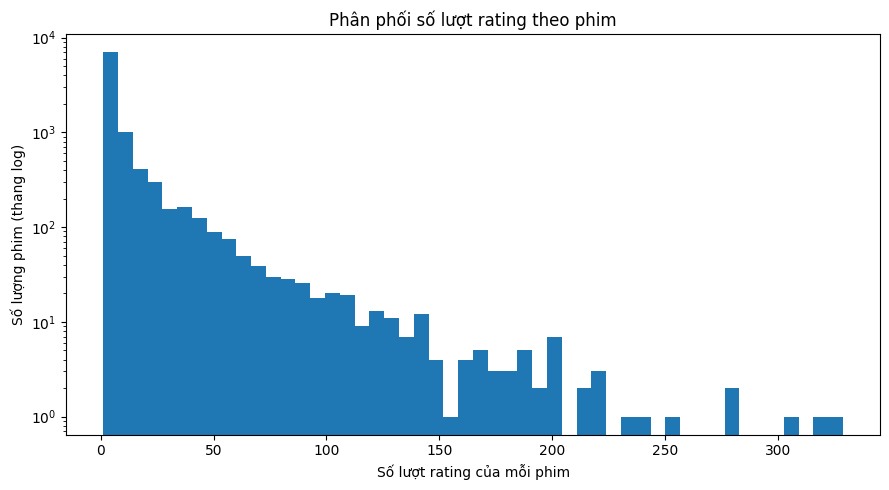

In [7]:
# Biểu đồ phân phối số lượt rating/phim; trục y log để dễ nhìn phân phối lệch
plt.figure(figsize=(9, 5))
plt.hist(rated["rating_count"], bins=50)
plt.yscale("log")
plt.xlabel("Số lượt rating của mỗi phim")
plt.ylabel("Số lượng phim (thang log)")
plt.title("Phân phối số lượt rating theo phim")
plt.tight_layout()
plt.show()


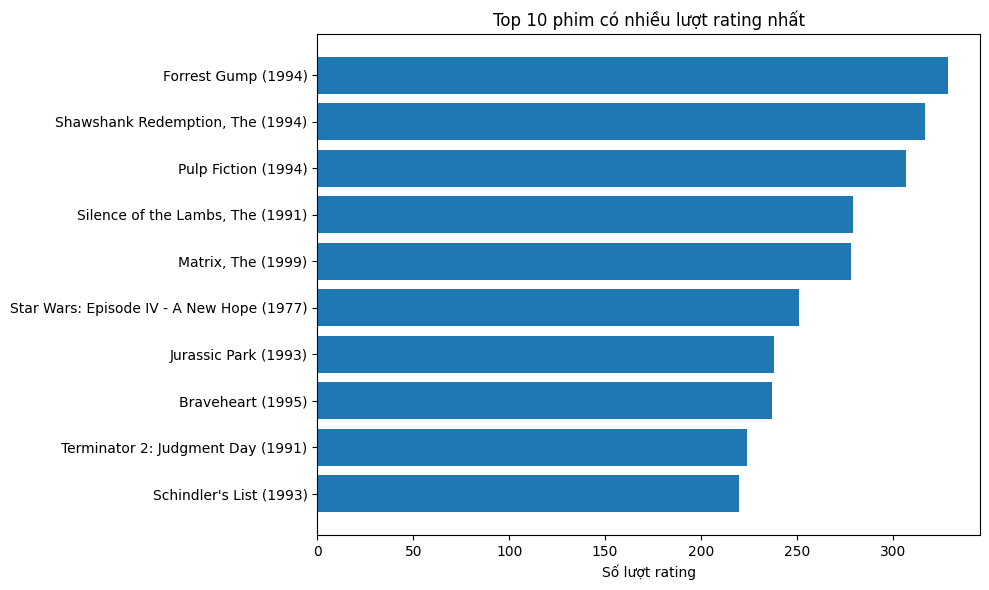

In [8]:
# Biểu đồ Top 10
plotdata = top10.sort_values("rating_count", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(plotdata["title"], plotdata["rating_count"])
plt.xlabel("Số lượt rating")
plt.title("Top 10 phim có nhiều lượt rating nhất")
plt.tight_layout()
plt.show()


In [9]:
# Tương quan Pearson giữa số lượt rating và rating trung bình
corr = rated["rating_count"].corr(rated["average_rating"])
print(f"Hệ số tương quan Pearson: {corr:.3f}")

Hệ số tương quan Pearson: 0.127
